# Setup

In [36]:
import pandas as pd

df = pd.read_csv("riftbound_all_price_history.csv")

In [37]:
# Start with the table's dimensions and a few rows so we can understand the unit of observation.
# This helps reveal whether each row represents a card, a price observation, or another entity.
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())



Rows: 457,039 | Columns: 12


,date,product_id,name,set,number,printing,market_price_usd,url,snapshot_date,low,market,tickerMint_url
0,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-29,349.99,NaN,https://tickermint.cards/card/712806
1,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-30,349.99,NaN,https://tickermint.cards/card/712806
2,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-08-31,349.92,NaN,https://tickermint.cards/card/712806
3,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-01,349.92,NaN,https://tickermint.cards/card/712806
4,NaN,712806,Legacy - Booster Display,Legacy,NaN,Normal,NaN,https://tickermint.cards/card/712806,2026-09-02,349.99,NaN,https://tickermint.cards/card/712806


In [38]:
# Inspect column types and non-null counts before choosing cleaning or analysis steps.
# Types can expose values that were loaded as text even though they should be numeric or dates.
df.info()

# Summarize missingness; percentages make it easier to prioritize columns with substantial gaps.
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing.loc[missing["missing_count"] > 0].sort_values("missing_percent", ascending=False))

# Exact duplicate rows may indicate repeated observations or an upstream data issue.
print(f"Exact duplicate rows: {df.duplicated().sum():,}")



<class 'pandas.DataFrame'>
RangeIndex: 457039 entries, 0 to 457038
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   date              450922 non-null  str    
 1   product_id        457039 non-null  int64  
 2   name              457039 non-null  str    
 3   set               457039 non-null  str    
 4   number            443336 non-null  str    
 5   printing          457039 non-null  str    
 6   market_price_usd  450922 non-null  float64
 7   url               457039 non-null  str    
 8   snapshot_date     457039 non-null  str    
 9   low               457039 non-null  float64
 10  market            438907 non-null  float64
 11  tickerMint_url    457039 non-null  str    
dtypes: float64(3), int64(1), str(8)
memory usage: 41.8 MB


,missing_count,missing_percent
market,18132,3.97
number,13703,3.00
date,6117,1.34
market_price_usd,6117,1.34


Exact duplicate rows: 0


In [39]:
# Check what the difference is between data and snapshot_date
df[['product_id','name','date', 'snapshot_date']]

,product_id,name,date,snapshot_date
0,712806,Legacy - Booster Display,NaN,2026-08-29
1,712806,Legacy - Booster Display,NaN,2026-08-30
2,712806,Legacy - Booster Display,NaN,2026-08-31
3,712806,Legacy - Booster Display,NaN,2026-09-01
4,712806,Legacy - Booster Display,NaN,2026-09-02
...,...,...,...,...
457034,672088,Aspirant's Climb,2026-10-11,2026-10-07
457035,672088,Aspirant's Climb,2026-10-11,2026-10-08
457036,672088,Aspirant's Climb,2026-10-11,2026-10-09
457037,672088,Aspirant's Climb,2026-10-11,2026-10-10


In [40]:
#Looks like date is the day the dataset was downloaded
#From this I know we can drop date and the url columns as they will not be releveant to the market analysis
df['date'].unique()

<StringArray>
[nan, '2026-10-11']
Length: 2, dtype: str

In [41]:
# Drop unnecessary columns and rows with missing market prices
# Change the data types of certain columns so they are more accurate
df_cleaned = df[df['market_price_usd'].notna()].drop(columns=['date', 'url', 'tickerMint_url'])

df_cleaned['market_price_usd'] = df_cleaned['market_price_usd'].astype(float)
df_cleaned['product_id'] = df_cleaned['product_id'].astype(int)
df_cleaned['snapshot_date'] = pd.to_datetime(df_cleaned['snapshot_date'])
df_cleaned.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
167,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-01,299.99,NaN
168,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-02,295.00,NaN
169,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-03,295.00,NaN
170,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-04,295.00,295.0
171,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-05,295.00,295.0


# Since the dataset combines both sealed and singles I believe it is important to seperate the 2 in distinct datasets

In [42]:
singles = df_cleaned[df_cleaned['number'].notna()]
singles.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
741,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-10,1250.0,NaN
742,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-11,1100.0,NaN
743,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-12,1100.0,NaN
744,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-13,1100.0,NaN
745,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.0,2026-09-14,990.0,NaN


In [43]:
sealed = df_cleaned[df_cleaned['number'].isna()]
sealed.head()

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
167,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-01,299.99,NaN
168,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-02,295.00,NaN
169,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-03,295.00,NaN
170,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-04,295.00,295.0
171,714486,Gift of the Rift Bundle,Gift of the Rift Bundle,NaN,Normal,288.59,2026-09-05,295.00,295.0


# Singles Data Cleaning & Exploration
### Start with this to try to spot any trends

In [44]:
singles 

,product_id,name,set,number,printing,market_price_usd,snapshot_date,low,market
741,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-10,1250.0,NaN
742,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-11,1100.0,NaN
743,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-12,1100.0,NaN
744,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-13,1100.0,NaN
745,716012,"Ambessa, The Wolf (T1 Worlds Champion Signatur...",T1 2025 Worlds Champion Bundles,T1S 001/005,Foil,535.00,2026-09-14,990.0,NaN
...,...,...,...,...,...,...,...,...,...
457034,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-07,30.0,43.57
457035,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-08,30.0,42.77
457036,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-09,30.0,41.83
457037,672088,Aspirant's Climb,Riftbound Worlds Bundle 2025,276a/298,Foil,41.83,2026-10-10,30.0,41.83


In [45]:
singles.groupby('product_id')['market_price_usd'].mean()

product_id
652771       0.20
652772       0.16
652773       0.14
652774       0.33
652775       0.21
           ...   
716021    1498.00
716026    1300.00
716035    1233.33
721767       0.10
721871     300.00
Name: market_price_usd, Length: 1439, dtype: float64

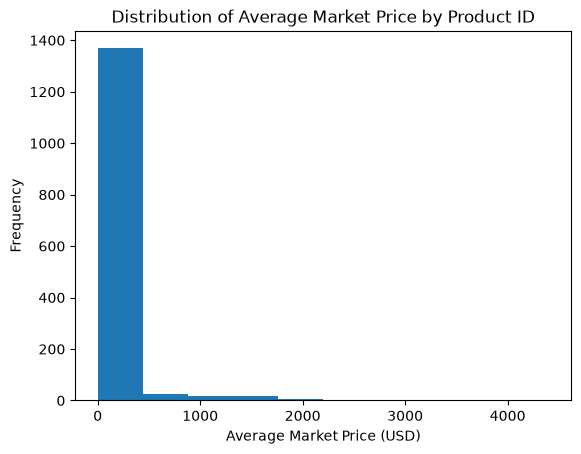

In [46]:
import matplotlib.pyplot as plt

singles.groupby('product_id')['market_price_usd'].mean().plot(kind='hist', bins = 10)
plt.xlabel('Average Market Price (USD)')
plt.ylabel('Frequency')
plt.title('Distribution of Average Market Price by Product ID')
plt.show()

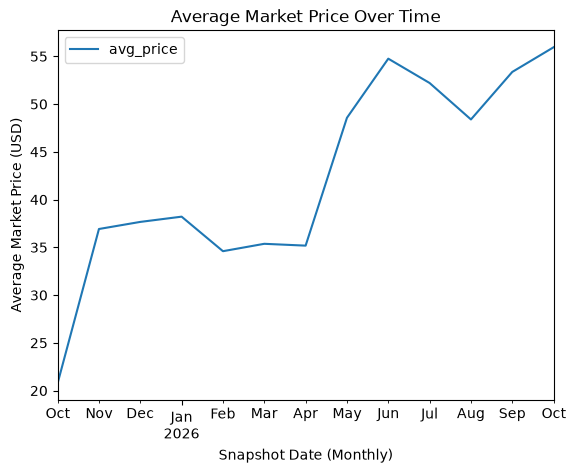

In [47]:
monthly = singles.groupby(
    singles['snapshot_date'].dt.to_period('M')
).agg(
    avg_price=('market_price_usd', 'mean'),
    card_count=('market_price_usd', 'count')
)

monthly.plot(y='avg_price', kind='line')
plt.xlabel('Snapshot Date (Monthly)')
plt.ylabel('Average Market Price (USD)')
plt.title('Average Market Price Over Time')
plt.show()

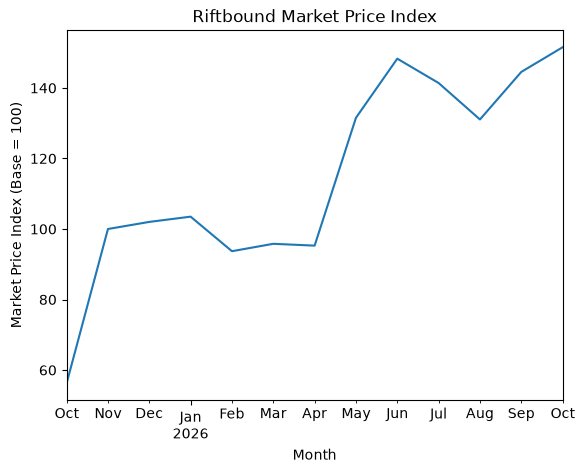

In [48]:
monthly['price_index'] = (
    monthly['avg_price'] / monthly['avg_price'].iloc[1]
) * 100

monthly['price_index'].plot(kind='line')

plt.xlabel('Month')
plt.ylabel('Market Price Index (Base = 100)')
plt.title('Riftbound Market Price Index')
plt.show()

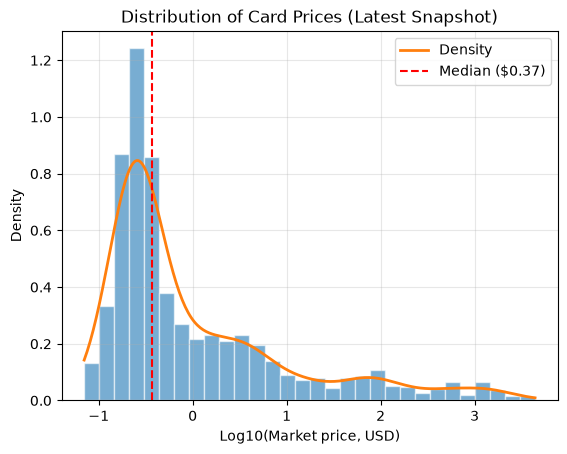

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

latest = singles[singles['snapshot_date'] == singles['snapshot_date'].max()]
prices = latest['market_price_usd']
log_data = np.log10(prices[prices > 0].dropna())   # log10(0) = -inf breaks the plot

# Histogram as density so the line is on the same scale
plt.hist(log_data, bins=30, density=True, alpha=0.6, edgecolor="white")

# Smooth density line (KDE)
x = np.linspace(log_data.min(), log_data.max(), 300)
plt.plot(x, gaussian_kde(log_data)(x), linewidth=2, label="Density")

# Optional: vertical median line
plt.axvline(log_data.median(), color="red", linestyle="--", label=f"Median (${10**log_data.median():.2f})")

plt.xlabel("Log10(Market price, USD)")
plt.ylabel("Density")
plt.title("Distribution of Card Prices (Latest Snapshot)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()